# 04 Agrupacion de proveedores duplicados

Este notebook responde al objetivo específico 3, que consiste en agrupar las llaves de proveedor que corresponden a la misma empresa y recalcular el gasto consolidado. Es un problema no supervisado, así que usamos la agrupación aglomerativa de la práctica 3.

Comparamos cada proveedor (llave entidad + codigo) con los demás por el nombre normalizado de la entrega 1, es decir, en mayúsculas, sin puntuación y sin formas societarias como INC o LTD. La distancia entre dos proveedores es 1 menos la similitud de Levenshtein de sus nombres. Además, dos llaves de entidades distintas del Banco no se pueden unir, así que su distancia se fija en 1.

Cómo lo evaluamos (comentario de la entrega 1):

1. Con la silueta, para escoger el criterio de enlace.
2. Revisando que ningún grupo absorba demasiadas llaves (efecto cadena).
3. Con la revisión del Banco de los 20 grupos de mayor gasto, que marca si las llaves son la misma empresa.

Los nombres reales los usamos solo en memoria para calcular las distancias, y el notebook no imprime ningún nombre.

## 1. Configuracion y carga

In [1]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Levenshtein import ratio as lev_ratio
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
pd.set_option("display.width", 200)
pd.set_option("display.float_format","{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
RAW_PATH = "../data/raw/Spend_FA_x_Transit_x_User_ID.xlsx"
REVISION_BANCO = "../data/raw/Revision_casos_duplicados_Banco_respuesta.xlsx"
MONTO="Invoice total with tax (CAD)"

raw_df = pd.read_excel(RAW_PATH, dtype={"Invoice Number": str})

def separar_proveedor(nombre):
    if pd.isna(nombre):
        return (np.nan, np.nan, np.nan)
    m = re.match(r"^(.*)_(\d+)_(\d+)$", nombre) or re.match(r"^.*\((.*)_(\d+)_(\d+)\)$", nombre)
    return (m.group(1).strip(),m.group(2),m.group(3)) if m else (nombre.strip(),np.nan,np.nan)

FORMAS_LEGALES = r"\b(INC|INCORPORATED|LTD|LTEE|LIMITED|LLC|LLP|LP|L P|ULC|CORP|CORPORATION|CO|COMPANY|SAS|S A S|SA|S A|SAA|SRL|S R L|SPA|LTDA|PLC|GMBH|BV|DE CV|S DE RL|THE)\b"
def normalizar_nombre(nombre):
    # mismas reglas de la entrega 1 para poder comparar los grupos
    if pd.isna(nombre):
        return np.nan
    n=re.sub(r"[^A-Z0-9 ]", " ", str(nombre).upper())
    n = re.sub(FORMAS_LEGALES, " ", n)
    return re.sub(r"\s+", " ", n).strip()
df=raw_df[["Invoice Supplier Name", "Invoice Status", MONTO]].copy()
df[["nombre","entidad","codigo"]] = pd.DataFrame(df["Invoice Supplier Name"].apply(separar_proveedor).tolist(),index=df.index)
df["llave"] = df["entidad"] + "_" + df["codigo"]
llaves=sorted(df["llave"].dropna().unique())
mapa = {k: f"PROV_{i:04d}" for i,k in enumerate(llaves,start=1)}  # mismos seudónimos que en la entrega 1
df["proveedor_id"]=df["llave"].map(mapa)
del raw_df

prov = (df.dropna(subset=["llave"]).groupby("proveedor_id")
            .agg(nombre=("nombre", "first"), entidad=("entidad", "first"), facturas=("llave", "size"))
            .reset_index())
gasto = df[df["Invoice Status"] == "approved"].groupby("proveedor_id")[MONTO].sum()
prov["gasto_aprobado"] = prov["proveedor_id"].map(gasto).fillna(0)
prov["nombre_norm"] = prov["nombre"].apply(normalizar_nombre)
prov=prov.drop(columns="nombre")  # desde aquí solo queda el nombre normalizado y no se imprime
print(f"Proveedores: {len(prov):,} | entidades del Banco: {prov['entidad'].nunique()} | gasto aprobado: {prov['gasto_aprobado'].sum() / 1e6:,.1f} millones de CAD")

Proveedores: 3,354 | entidades del Banco: 4 | gasto aprobado: 11,168.6 millones de CAD


## 2. Matriz de distancias

Distancia = 1 − similitud de Levenshtein entre los nombres normalizados, solo dentro de la misma entidad. Entre entidades distintas la distancia es 1.

In [2]:
n = len(prov)
# entre entidades distintas la distancia es 1: no es un duplicado del maestro
D = np.ones((n, n))
np.fill_diagonal(D, 0)
nombres = prov["nombre_norm"].fillna("").tolist()
for ent, idx in prov.groupby("entidad").indices.items():
    for a in range(len(idx)):
        for b in range(a + 1,len(idx)):
            i,j = idx[a],idx[b]
            D[i, j]=D[j, i]=1 - lev_ratio(nombres[i], nombres[j])
sup = D[np.triu_indices(n,1)]
print(f"Matriz de {n:,} x {n:,} | pares con el mismo nombre normalizado: {int((sup == 0).sum()):,} | pares con similitud >= 0,90: {int((sup <= 0.10).sum()):,}")

Matriz de 3,354 x 3,354 | pares con el mismo nombre normalizado: 36 | pares con similitud >= 0,90: 68


## 3. Escogencia del enlace y del umbral

Como no se sabe cuántas empresas hay, el corte lo hacemos con distance_threshold (n_clusters=None). El umbral es la distancia máxima para unir dos grupos. Por ejemplo, 0,10 equivale a nombres con al menos 90% de similitud. Ward no lo usamos porque solo admite distancia euclidiana, así que comparamos los enlaces complete y average, y también single para mostrar el efecto cadena.

Para cada combinación calculamos cuatro cosas: la silueta con la matriz de distancias, el número de grupos con más de una llave, el tamaño del grupo más grande y el gasto que queda en grupos con varias llaves.

In [3]:
filas = []
for enlace in ["single", "complete", "average"]:
    for umbral in [0.05,0.10,0.15,0.20]:
        modelo = AgglomerativeClustering(n_clusters=None, distance_threshold=umbral, linkage=enlace, metric="precomputed")
        etiquetas = modelo.fit_predict(D)
        tam = pd.Series(etiquetas).value_counts()
        multi = tam[tam > 1].index
        filas.append({"enlace": enlace, "umbral": umbral, "grupos": modelo.n_clusters_,
                     "grupos con 2+ llaves": len(multi), "llaves en esos grupos": int(tam[tam > 1].sum()),
                        "grupo más grande": int(tam.max()),"silueta": silhouette_score(D,etiquetas,metric="precomputed"),
                      "% gasto en grupos con 2+ llaves": prov.loc[np.isin(etiquetas, multi), "gasto_aprobado"].sum() / prov["gasto_aprobado"].sum() * 100})
comparacion = pd.DataFrame(filas)
comparacion

,enlace,umbral,grupos,grupos con 2+ llaves,llaves en esos grupos,grupo más grande,silueta,% gasto en grupos con 2+ llaves
0,single,0.050,3316,31,69,5,0.019,8.347
1,single,0.100,3297,48,105,5,0.025,10.710
2,single,0.150,3213,111,252,7,0.041,16.288
3,single,0.200,2924,172,602,61,0.046,39.846
4,complete,0.050,3317,32,69,5,0.019,8.347
5,complete,0.100,3299,48,103,5,0.025,10.704
6,complete,0.150,3228,114,240,6,0.041,16.125
7,complete,0.200,3073,235,516,6,0.062,36.803
8,average,0.050,3317,32,69,5,0.019,8.347
9,average,0.100,3299,48,103,5,0.025,10.704


En este problema la silueta no basta para escoger el umbral. Casi todos los proveedores quedan solos en su grupo, y scikit-learn le asigna silueta 0 a un grupo de un solo elemento. Como resultado, la silueta sube siempre que se sube el umbral, ya que une más llaves aunque sean empresas distintas. Por ejemplo, con umbral 0,20 (80% de similitud) se unen nombres que solo commparten palabras genéricas, y el gasto "duplicado" sata a más de un tercio del total, lo cuál no es creíble.

Cómo llegamos al umbral de 0,10. Probamos los tres enlaces con cuatro umbrales (tabla de arriba):

- Con 0,05 salen 32 grupos y 8,3% del gasto. Es muy estricto, dado que deja por fuera nombres que solo cambian en una letra o una abreviatura.
- Con 0,10 salen 48 grupos, 10,7% del gasto y el grupo más grande tiene 5 llaves. Esta es la misma regla de 90% de similitud de la entrega 1.
- Con 0,15 los grupos se duplican (113) y el gasto sube a 16%.
- Con 0,20 la silueta es la más alta, pero se juntaría el 36,5% del gasto, y con enlace single sale un grupo de 61 llaves (efecto cadena). Que un tercio del gasto sea del mismo proveedor repetido no es creíble.

Lo que no funcionó fue escoger el umbral solo con la silueta, porque sube siempre. Por eso, usamos la silueta para el enlace (average, que nunca hace cadena) y fijamos el umbral en 0,10. Además, esta es la regla que usamos en el Excel de 20 grupos que le mandamos al Banco, así que su respuesta valida directamente esta decisión. El Banco confirmó que 17 de los 20 grupos son la misma empresa (sección 6), lo que respalda el umbral. Por último, los umbrales 0,15 y 0,20 quedan como el rango superior del gasto que podría estar sin consolidar.

In [4]:
ENLACE,UMBRAL = "average",0.10  # 0,10 y no 0,20: con 0,20 la silueta subía pero se juntaba demasiado gasto
elegida = comparacion[(comparacion["enlace"] == ENLACE) & (comparacion["umbral"] == UMBRAL)].iloc[0]
print(f"Configuración escogida: enlace {ENLACE}, umbral {UMBRAL} (similitud de nombre >= {1 - UMBRAL:.0%}) | "
    f"silueta {elegida['silueta']:.3f} | grupo más grande {elegida['grupo más grande']} llaves")

Configuración escogida: enlace average, umbral 0.1 (similitud de nombre >= 90%) | silueta 0.025 | grupo más grande 5 llaves


## 4. Dendrograma

Lo diibujamos para la entidad con más proveedores, con el mismo enlace y truncado a las ultimas 30 uniones para que se pueda leer. La línea roja marca elumbral escogido.

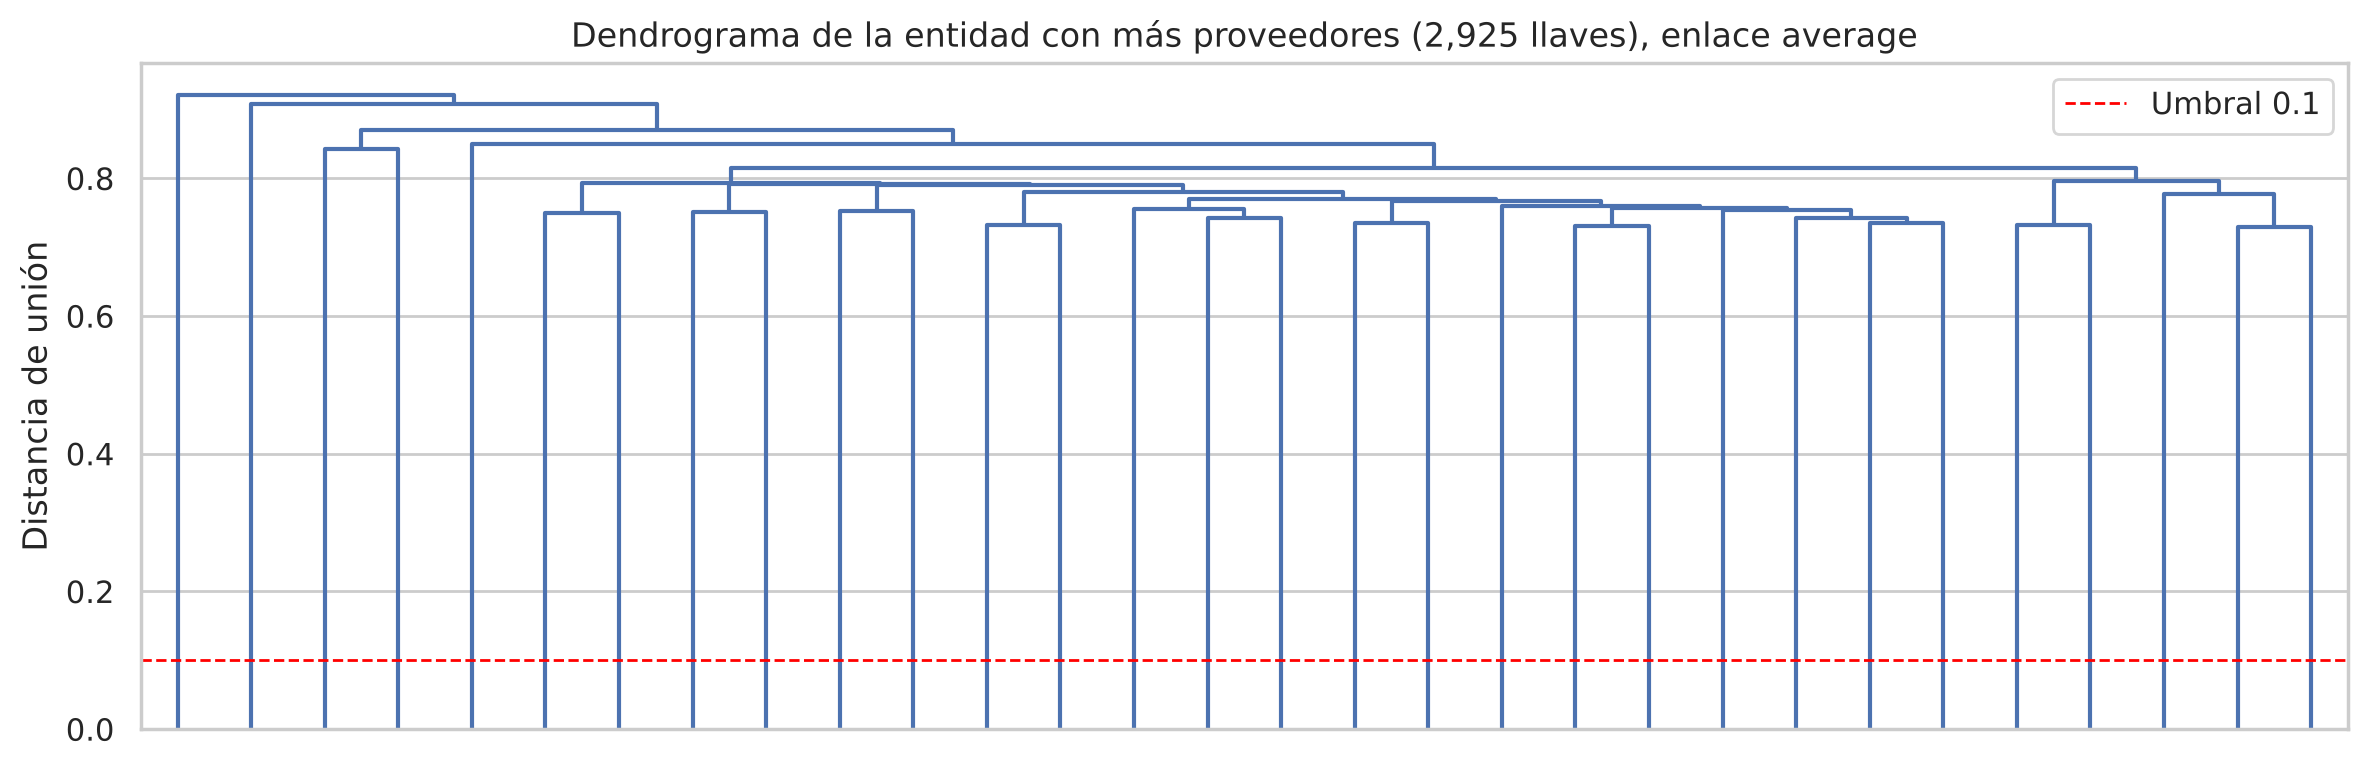

In [5]:
ent_grande = prov["entidad"].value_counts().index[0]
idx = prov.index[prov["entidad"] == ent_grande].to_numpy()
jerarquia=linkage(squareform(D[np.ix_(idx,idx)],checks=False),method=ENLACE)
plt.figure(figsize=(12,4))
dendrogram(jerarquia, truncate_mode="lastp", p=30, no_labels=True)
plt.axhline(UMBRAL,color="red",ls="--",lw=1,label=f"Umbral {UMBRAL}")
plt.ylabel("Distancia de unión"); plt.title(f"Dendrograma de la entidad con más proveedores ({len(idx):,} llaves), enlace {ENLACE}")
plt.legend(); plt.tight_layout(); plt.show()

La mayoría de las uniones ocurren a distancias altas, dado que casi todos los proveedores tienen nombres muy distintos. Solo unas pocas uniones quedan por debajo del umbral, y estas son las llaves con nombre igual o casi igual.

## 5. Grupos resultantes y gasto consolidado

In [6]:
modelo = AgglomerativeClustering(n_clusters=None, distance_threshold=UMBRAL, linkage=ENLACE, metric="precomputed")
prov["grupo"] = modelo.fit_predict(D)
tam = prov["grupo"].value_counts()
prov["llaves_en_grupo"] = prov["grupo"].map(tam)
multi = prov[prov["llaves_en_grupo"] > 1]
# el Banco dijo q intragrupo son solo las llaves con el nombre Bank of Nova Scotia
multi = multi.assign(intragrupo=multi["nombre_norm"].str.contains(r"BANK OF NOVA SCOTIA", na=False))
grupos = (multi.groupby("grupo").agg(llaves=("proveedor_id", "size"), gasto_aprobado=("gasto_aprobado", "sum"),
                                     facturas=("facturas", "sum"), entidad=("entidad", "first"), intragrupo=("intragrupo", "all"))
             .sort_values("gasto_aprobado", ascending=False))
grupos.index = [f"GRUPO_P{i:03d}" for i in range(1, len(grupos) + 1)]
print(f"Grupos con 2 o más llaves: {len(grupos)} | llaves involucradas: {int(grupos['llaves'].sum())} | "
    f"gasto en esos grupos: {grupos['gasto_aprobado'].sum() / 1e6:,.1f} millones de CAD "
        f"({grupos['gasto_aprobado'].sum() / prov['gasto_aprobado'].sum():.1%} del gasto aprobado)")
sin_intra = grupos[~grupos["intragrupo"]]
print(f"Sin los grupos intragrupo del Banco: {len(sin_intra)} grupos | gasto {sin_intra['gasto_aprobado'].sum() / 1e6:,.1f} millones de CAD "
      f"({sin_intra['gasto_aprobado'].sum() / prov['gasto_aprobado'].sum():.1%} del gasto aprobado) | intragrupo excluidos: {int(grupos['intragrupo'].sum())}")
grupos.head(20)

Grupos con 2 o más llaves: 48 | llaves involucradas: 103 | gasto en esos grupos: 1,195.5 millones de CAD (10.7% del gasto aprobado)
Sin los grupos intragrupo del Banco: 46 grupos | gasto 996.0 millones de CAD (8.9% del gasto aprobado) | intragrupo excluidos: 2


,llaves,gasto_aprobado,facturas,entidad,intragrupo
GRUPO_P001,2,"524,582,978.360",748,10001,False
GRUPO_P002,5,"197,142,141.180",378,10001,True
GRUPO_P003,2,"187,244,184.060",838,10001,False
GRUPO_P004,2,"78,565,723.900",1158,10001,False
GRUPO_P005,2,"49,528,370.870",268,10001,False
GRUPO_P006,2,"38,645,967.130",108,10001,False
GRUPO_P007,2,"34,857,176.790",447,10001,False
GRUPO_P008,2,"13,705,255.230",439,10001,False
GRUPO_P009,2,"13,044,767.050",39,10001,False
GRUPO_P010,2,"8,318,816.580",120,10001,False


Qué cambia en el ranking de proveedores. Si se suman las llaves de cada grupo, algunas empresas suben en el ranking de gasto. Esto es lo que el área de Procurement necesita para negociar con el gasto real de cada empresa.

In [7]:
prov["empresa"] = np.where(prov["llaves_en_grupo"] > 1, "G" + prov["grupo"].astype(str), prov["proveedor_id"])
rank_antes = prov.sort_values("gasto_aprobado",ascending=False).reset_index(drop=True)
rank_despues = prov.groupby("empresa")["gasto_aprobado"].sum().sort_values(ascending=False).reset_index()
print(f"Gasto de los 10 proveedores más grandes: antes {rank_antes['gasto_aprobado'].head(10).sum() / prov['gasto_aprobado'].sum():.1%} "
    f"| después de consolidar {rank_despues['gasto_aprobado'].head(10).sum() / prov['gasto_aprobado'].sum():.1%}")
print(f"Empresas distintas: antes {len(prov):,} llaves | después {len(rank_despues):,}")

Gasto de los 10 proveedores más grandes: antes 31.9% | después de consolidar 32.9%
Empresas distintas: antes 3,354 llaves | después 3,299


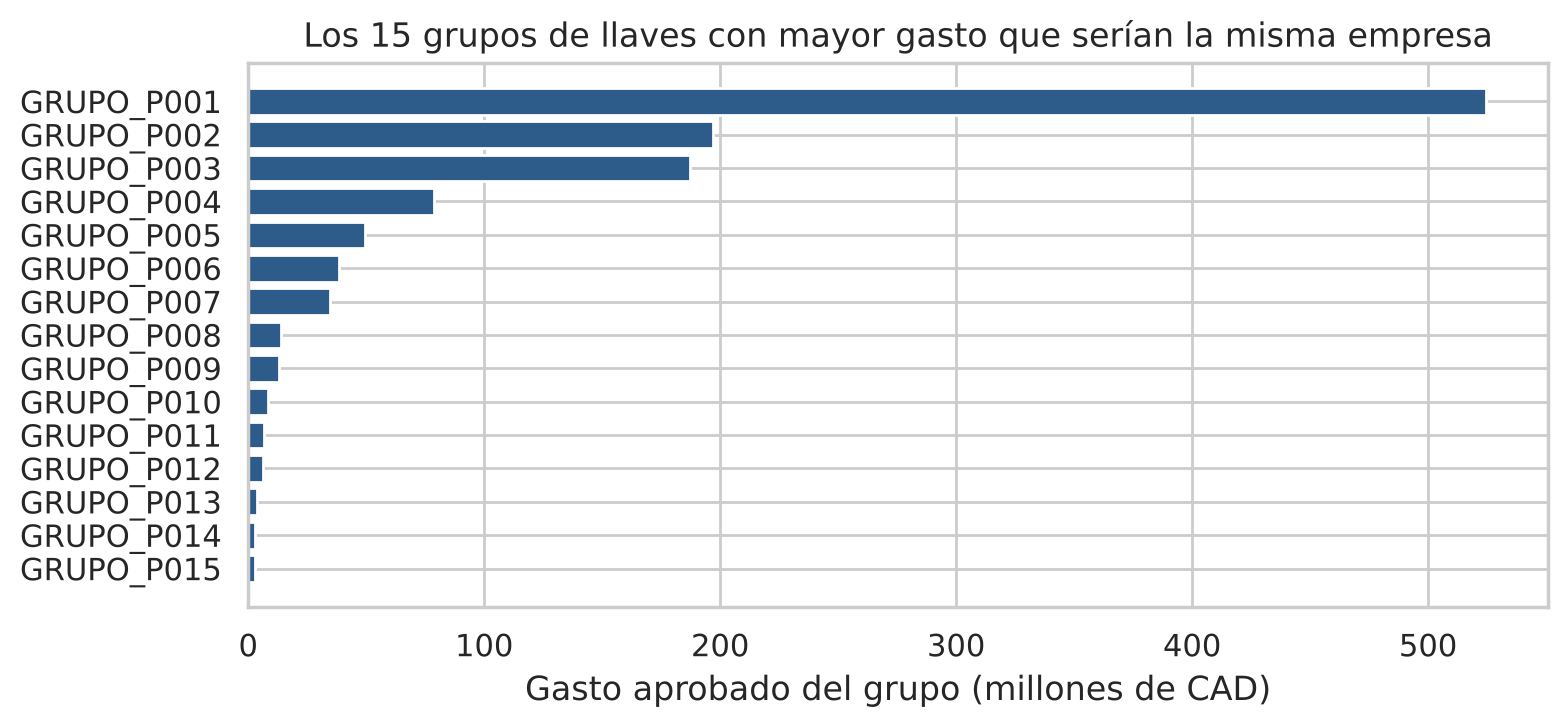

In [8]:
fig,ax = plt.subplots(figsize=(8,3.8))
top = grupos.head(15)
ax.barh(top.index[::-1], top["gasto_aprobado"][::-1] / 1e6, color="#2E5C8A")
ax.set_xlabel("Gasto aprobado del grupo (millones de CAD)")
ax.set_title("Los 15 grupos de llaves con mayor gasto que serían la misma empresa")
plt.tight_layout(); plt.show()

## 6. Validación con el Banco

El Banco revisó los 20 gupos del Excel, que son los de mayor gasto con nombre normalizado igual o similitud de 0,90 o más. Para cada uno respondio si las llaves son la misma empresa y dejó un comentario por llave. Con los comentarios, cada grupo queda en una de cinco categorías:

- Duplicado nuevo: el Banco no lo tenía identificado y va a trasladar el gasto y desactivar la llave.
- Duplicado ya desactivado: el Banco ya lo había encontrado antes.
- Misma empresa con llaves para usos distintos: un contrato específico, otro proyeto u otra área de compras. El Banco nos explicó que esto pasa en muy pocos casos y con empresas con las que tiene contratos grandes, por ejemplo una firma de consultoría con una llave aparte para ver el gasto de un contrato específico.
- Intragrupo: llaves con el nombre Bank of Nova Scotia, que se usan para compras internas por país. El Banco nos aclaró que solo estas son intragrupo, así que basta con ese nombre para marcarlas.
- Empresas distintas: la misma marca con una sociedad distinta en cada país.

In [9]:
def categoria(sub):
    com = " ".join(sub["Comentario"].astype(str).str.lower())
    if "trasladar gasto y desactivar" in com:
        return "Duplicado nuevo"
    if "desactiv" in com or "inactivo" in com:
        return "Duplicado ya desactivado"
    if sub["¿Es la misma empresa?"].astype(str).str.strip().str.lower().isin(["no"]).all():
        return "Empresas distintas"
    if "intragroup" in com:
        return "Intragrupo"
    return "Misma empresa, usos distintos"

if os.path.exists(REVISION_BANCO):
    rev = pd.read_excel(REVISION_BANCO, sheet_name="Proveedores")
    rev["misma"] = rev["¿Es la misma empresa?"].astype(str).str.strip().str.lower().isin(["sí", "si"])
    cat = rev.groupby("Grupo").apply(categoria, include_groups=False).rename("categoria")
    resumen_val = (rev.groupby("Grupo").agg(misma=("misma", "all"), gasto=("Gasto aprobado (CAD)", "sum")).join(cat))
    print(resumen_val["categoria"].value_counts().to_string())
    print(f"\nGrupos confirmados como la misma empresa: {int(resumen_val['misma'].sum())} de {len(resumen_val)}")
    trasladar = rev[rev["Comentario"].astype(str).str.lower().str.contains("trasladar gasto y desactivar")]
    print(f"Llaves duplicadas nuevas a desactivar: {len(trasladar)} | gasto a trasladar: {trasladar['Gasto aprobado (CAD)'].sum():,.0f} CAD")
    validado = resumen_val[resumen_val["misma"] & (resumen_val["categoria"] != "Intragrupo")]["gasto"].sum()
    print(f"Gasto consolidado validado (misma empresa, sin intragrupo): {validado / 1e6:,.1f} millones de CAD "
          f"({validado / prov['gasto_aprobado'].sum():.1%} del gasto aprobado)")
else:
    print("Pendiente: el Banco todavía no ha devuelto la revisión.")

categoria
Duplicado ya desactivado         6
Misma empresa, usos distintos    4
Duplicado nuevo                  4
Intragrupo                       3
Empresas distintas               3

Grupos confirmados como la misma empresa: 17 de 20


Llaves duplicadas nuevas a desactivar: 6 | gasto a trasladar: 1,509,047 CAD
Gasto consolidado validado (misma empresa, sin intragrupo): 662.3 millones de CAD (5.9% del gasto aprobado)


Lo que dice la revisión:

- 17 de los 20 grupos son la misma empresa, así que comparar nombres sí encuentra llaves repetidas. Los 3 que no lo son tienen la misma marca pero una sociedad distinta por país, por ejemplo contratos de Canadá y del Reino Unido. La normalización quita las formas legales como INC o LLP y por eso los junta. Para evitar ese error, se podría agregar el país de la llave.
- 4 grupos son duplicados que el Banco no tenía identificados y ahora va a desactivar, y otros 6 ya los habia desactivado antes. Es decir, la mitad de los grupos eran duplicados reales del maestro, y 4 deellos eran nuevos para el Banco.
- Los grupos restantes son la misma empresa pero con llaves para usos distintos, o compras intragrupo. Para el Banco esas llaves están bien creadas y no se deben borrar. Además, los 3 grupos intragrupo tienen el nombre Bank of Nova Scotia, que es la regla que nos dio el Banco.

Con esta retroalimentación hicimos dos ajustes. Primero, excluimos de la agrupacion las llaves intragrupo del Banco (sección 5). Segundo, como gasto consolidado validado reportamos solo el de los grupos que el Banco confirmó.

## 7. Resumen

- La agrupación aglomerativa con la distancia de Levenshtein encuentra las llaves de proveedor con nombre igual o casi igual dentro de la misma entidad del Banco.
- El enlace lo escogimos por silueta (average). En cambio, el umbral lo fijamos en 90% de similitud, la regla de la entrega 1, porque en este problema la silueta sube siempre con el umbral y no sirve sola para escoger el corte.
- El alcance es dentro de cada entidad del Banco. Dos llaves en entidades distintas pueden ser el mismo proveedor contratado por dos sociedades, y eso no es un duplicado del maestro. Por eso, el porcentaje es menor que el 24,4% de la entrega 1, que contaba nombres repetidos también entre entidades.
- El gasto en grupos con varias llaves es un gasto sin consolidar. Este solo sevuelve gasto consolidado cuando el Banco confirma que las llaves son la misma empresa, como pasó con 17 de los 20 grupos revisados.
- Con la revisión del Banco excluimos las llaves intragrupo, y el gatso consolidado validado pasó de 0% a 5,9% del gasto aprobado. Además, el Banco va a desactivar 6 llaves duplicadas que no tenía identificadas, con 1,51 millones de CAD de gasto a trasladar.
- El nombre no basta para confirmar, ya que dos empresas distintas pueden tener nombres parecidos. Por lo tanto, la validación del Banco es parte del proceso, y un maestro de proveedores con identificación tributaria mejoraría el resultado.